<div style="background:#A4243B;color:white;padding:18px 22px;border-radius:10px;border-bottom:5px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/assets/logo_transparent.png" alt="Algo Professor" style="float:right;height:74px;background:white;border-radius:8px;padding:4px 8px">
<div style="font-size:13px;letter-spacing:2px;color:#F6EBC4">ALGOPROFESSOR · AI SCIENTIST HANDS-ON · SUNDAY 2</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Deep Learning with PyTorch</div>
<div style="font-size:15px;margin-top:6px">Hours 6–10 · 2 h hands-on teaching + 3 h real-time project work · GitHub submission by 18:00</div>
</div>

| Hour | Mode | Focus | Dataset |
|---|---|---|---|
| 6 | TEACH | Tensors, autograd, training loop from scratch | Fashion-MNIST |
| 7 | TEACH | CNNs, augmentation, mixed precision | CIFAR-10 |
| 8 | BUILD | LeafDoctor: data pipeline, splits, leakage checks | PlantVillage (apple classes) |
| 9 | BUILD | CNN vs tiny Vision Transformer, Grad-CAM, error analysis | PlantVillage |
| 10 | BUILD | Robustness, INT8 quantisation, ONNX export, model card | PlantVillage + simulated field shift |

> **Compute note.** This notebook is sized to run on a laptop CPU in a few minutes. In class on a GPU, raise image size and epochs,
> and swap the from-scratch CNN for a pretrained EfficientNet/ViT (code given in Hour 9).

In [1]:
# ---------- Setup (run once) ----------
import os, pathlib, urllib.request, warnings, time, json, random
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Data cache lives at the repository root (data/ is git-ignored); figures go next to the notes.
DATA = pathlib.Path(os.environ.get("AP_DATA", "../../data")); DATA.mkdir(parents=True, exist_ok=True)
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)

def fetch(url, name):
    """Download a file once into the shared data cache and return its path."""
    p = DATA / name
    if not p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, p)
    return p

# AlgoProfessor colour palette
NAVY, GOLD, GREEN, PURPLE = "#0B1F3A", "#C9A227", "#1E7B5A", "#6A3D9A"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
                     "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=[NAVY, GOLD, GREEN, PURPLE, "#A4243B", "#C25E00"])})
print("Setup complete. Data cache:", DATA.resolve())

Setup complete. Data cache: /home/claude/build/data


In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
import gzip, subprocess, hashlib
from PIL import Image
torch.manual_seed(SEED); torch.set_num_threads(max(1, os.cpu_count() or 1))
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.15.0+cu132 | device: cpu


---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 6 — Tensors, autograd and the training loop from scratch

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Fashion-MNIST (70,000 images)</span>
**Skills:** <span style="color:#6A3D9A">PyTorch core, autograd, custom training loops, debugging loss curves</span>

### 6.1 Autograd in three lines

In [3]:
w = torch.tensor(3.0, requires_grad=True)
loss = (2 * w - 4) ** 2          # d(loss)/dw = 2*(2w-4)*2 = 8 at w=3
loss.backward()
print("loss =", loss.item(), "| gradient dL/dw =", w.grad.item())

loss = 4.0 | gradient dL/dw = 8.0


### 6.2 Load Fashion-MNIST (raw IDX files)

torch.Size([60000, 784]) torch.Size([10000, 784])


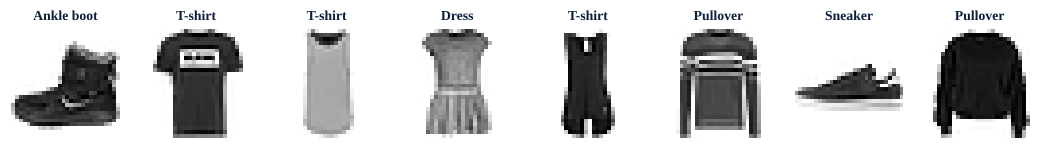

In [4]:
BASE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
def load_idx(name, kind):
    with gzip.open(fetch(BASE + name, "fmnist_" + name), "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=16 if kind == "img" else 8)
Xtr = torch.tensor(load_idx("train-images-idx3-ubyte.gz", "img").reshape(-1, 784), dtype=torch.float32) / 255.
ytr = torch.tensor(load_idx("train-labels-idx1-ubyte.gz", "lbl"), dtype=torch.long)
Xte = torch.tensor(load_idx("t10k-images-idx3-ubyte.gz", "img").reshape(-1, 784), dtype=torch.float32) / 255.
yte = torch.tensor(load_idx("t10k-labels-idx1-ubyte.gz", "lbl"), dtype=torch.long)
FM_CLASSES = ["T-shirt","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
print(Xtr.shape, Xte.shape)

fig, ax = plt.subplots(1, 8, figsize=(12, 1.8))
for i, a in enumerate(ax):
    a.imshow(Xtr[i].reshape(28, 28), cmap="gray_r"); a.set_title(FM_CLASSES[ytr[i]], fontsize=9); a.axis("off")
plt.show()

### 6.3 An MLP and a hand-written training loop

In [5]:
mlp = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-5)

def run_epoch(model, X, y, opt=None, bs=256):
    train = opt is not None; model.train(train)
    idx = torch.randperm(len(X)) if train else torch.arange(len(X))
    tot_loss, correct = 0.0, 0
    with torch.set_grad_enabled(train):
        for i in range(0, len(X), bs):
            b = idx[i:i+bs]; out = model(X[b]); loss = F.cross_entropy(out, y[b])
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(b); correct += (out.argmax(1) == y[b]).sum().item()
    return tot_loss / len(X), correct / len(X)

hist = []
for ep in range(1, 6):
    trl, tra = run_epoch(mlp, Xtr, ytr, opt); tel, tea = run_epoch(mlp, Xte, yte)
    hist.append((ep, trl, tel, tra, tea)); print(f"epoch {ep}: train loss {trl:.3f} acc {tra:.3f} | test loss {tel:.3f} acc {tea:.3f}")

epoch 1: train loss 0.660 acc 0.769 | test loss 0.464 acc 0.838


epoch 2: train loss 0.428 acc 0.846 | test loss 0.412 acc 0.852


epoch 3: train loss 0.379 acc 0.862 | test loss 0.384 acc 0.863


epoch 4: train loss 0.353 acc 0.872 | test loss 0.374 acc 0.864


epoch 5: train loss 0.332 acc 0.878 | test loss 0.357 acc 0.871


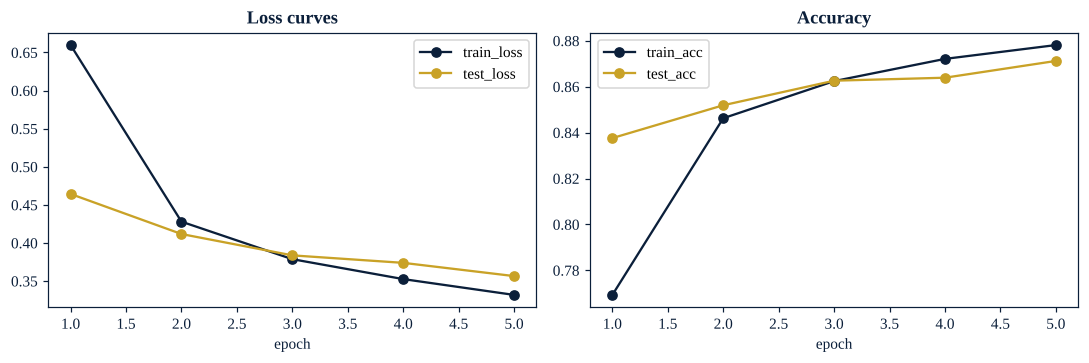

In [6]:
h = pd.DataFrame(hist, columns=["epoch", "train_loss", "test_loss", "train_acc", "test_acc"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
h.plot(x="epoch", y=["train_loss", "test_loss"], ax=ax[0], marker="o", title="Loss curves")
h.plot(x="epoch", y=["train_acc", "test_acc"], ax=ax[1], marker="o", title="Accuracy")
plt.tight_layout(); plt.savefig(FIG/"s2_mlp_curves.png", bbox_inches="tight"); plt.show()

**Reading loss curves:** if train loss keeps falling while test loss rises, the model is memorising (overfitting) —
add regularisation, augmentation or stop earlier.

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 7 — CNNs, data augmentation and mixed precision

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">CIFAR-10 (10,000-image test split)</span>
**Skills:** <span style="color:#6A3D9A">CNN design, augmentation, AMP training</span>

We use CIFAR-10's 10,000-image test split (1,000 per class) so this runs on a CPU. In class, use the full 60,000 images:
`torchvision.datasets.CIFAR10(root, download=True)`.

In [7]:
CIFAR_DIR = DATA / "cifar10_test"
if not CIFAR_DIR.exists():   # images mirrored on GitHub (YoongiKim/CIFAR-10-images)
    subprocess.run(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/YoongiKim/CIFAR-10-images {DATA}/_cifar && "
                   f"cd {DATA}/_cifar && git sparse-checkout set test && mv test {CIFAR_DIR}", shell=True, check=True)

def load_folder(root, size):
    classes = sorted(p.name for p in root.iterdir() if p.is_dir()); X, y, paths = [], [], []
    for ci, c in enumerate(classes):
        for f in sorted((root / c).iterdir()):
            X.append(np.asarray(Image.open(f).convert("RGB").resize((size, size)), dtype=np.uint8)); y.append(ci); paths.append(f)
    X = torch.tensor(np.stack(X)).permute(0, 3, 1, 2).float() / 255.
    return X, torch.tensor(y), classes, paths

Xc, yc, CIFAR_CLASSES, _ = load_folder(CIFAR_DIR, 32)
perm = torch.randperm(len(Xc)); tr, te = perm[:8000], perm[8000:]
mean, std = Xc[tr].mean((0, 2, 3), keepdim=True), Xc[tr].std((0, 2, 3), keepdim=True)   # statistics from TRAIN only
Xc = (Xc - mean) / std
print(Xc.shape, CIFAR_CLASSES)

torch.Size([10000, 3, 32, 32]) ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
def augment(x):
    """Random horizontal flip + random 4-pixel shifted crop, done on the batch tensor."""
    flip = torch.rand(len(x)) < 0.5; x = x.clone(); x[flip] = x[flip].flip(3)
    pad = F.pad(x, (4, 4, 4, 4), mode="reflect"); i, j = np.random.randint(0, 9, 2)
    return pad[:, :, i:i+x.shape[2], j:j+x.shape[3]]

class SmallCNN(nn.Module):
    def __init__(self, n_classes, c=(32, 64, 128)):
        super().__init__()
        layers, cin = [], 3
        for cout in c:
            layers += [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                       nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(cin, n_classes))
    def forward(self, x): return self.head(self.features(x))

def train_model(model, X, y, tr, te, epochs, lr=2e-3, aug=True, bs=128, amp=False):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * ((len(tr) + bs - 1) // bs))
    log = []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); idx = tr[torch.randperm(len(tr))]
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]; xb = augment(X[b]) if aug else X[b]
            with torch.autocast(device_type="cpu", dtype=torch.bfloat16, enabled=amp):
                loss = F.cross_entropy(model(xb), y[b])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        acc = evaluate_acc(model, X[te], y[te]); log.append(acc)
        print(f"epoch {ep}: held-out acc {acc:.3f}  ({time.time()-t0:.0f}s)")
    return log

@torch.no_grad()
def evaluate_acc(model, X, y, bs=512):
    model.eval(); return sum((model(X[i:i+bs]).argmax(1) == y[i:i+bs]).sum().item() for i in range(0, len(X), bs)) / len(X)

cnn_c = SmallCNN(10)
print("parameters:", sum(p.numel() for p in cnn_c.parameters()))
cifar_log = train_model(cnn_c, Xc, yc, tr, te, epochs=8)

parameters: 289194


epoch 1: held-out acc 0.344  (13s)


epoch 2: held-out acc 0.425  (13s)


epoch 3: held-out acc 0.353  (13s)


epoch 4: held-out acc 0.484  (14s)


epoch 5: held-out acc 0.590  (14s)


epoch 6: held-out acc 0.634  (16s)


epoch 7: held-out acc 0.685  (13s)


epoch 8: held-out acc 0.671  (13s)


In [9]:
# Mixed precision: same forward pass in bfloat16 — faster on modern hardware, nearly identical predictions
with torch.no_grad(), torch.autocast(device_type="cpu", dtype=torch.bfloat16):
    out_bf16 = cnn_c.eval()(Xc[te[:512]])
with torch.no_grad():
    out_fp32 = cnn_c(Xc[te[:512]])
print("prediction agreement fp32 vs bf16:", (out_bf16.argmax(1) == out_fp32.argmax(1)).float().mean().item())

prediction agreement fp32 vs bf16: 0.990234375


---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 8 — LeafDoctor: data pipeline, splits and leakage checks

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">PlantVillage — 4 apple classes, 3,171 leaf images</span>
**Skills:** <span style="color:#6A3D9A">Image datasets, stratified splits, leakage checks</span>

**Project P2 — LeafDoctor.** A farmer photographs an apple leaf; the app says *healthy*, *apple scab*, *black rot* or *cedar apple rust*.
We use the four apple classes of PlantVillage here; in class you can extend to all 38 classes.

In [10]:
PV_DIR = DATA / "plantvillage"
PV_CLASSES_WANTED = ["Apple___Apple_scab", "Apple___Black_rot", "Apple___Cedar_apple_rust", "Apple___healthy"]
if not PV_DIR.exists():   # sparse checkout of only the classes we need from the public PlantVillage repo
    subprocess.run(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/spMohanty/PlantVillage-Dataset {DATA}/_pv && "
                   f"cd {DATA}/_pv && git sparse-checkout set " + " ".join("raw/color/" + c for c in PV_CLASSES_WANTED) +
                   f" && mv raw/color {PV_DIR}", shell=True, check=True)

IMG = 64
Xp, yp, PV_CLASSES, pv_paths = load_folder(PV_DIR, IMG)
short = [c.split("___")[1].replace("_", " ") for c in PV_CLASSES]
print(Xp.shape); pd.Series(yp.numpy()).map(dict(enumerate(short))).value_counts()

torch.Size([3171, 3, 64, 64])


healthy             1645
Apple scab           630
Black rot            621
Cedar apple rust     275
Name: count, dtype: int64

exact duplicate images: 7


images after de-duplication: 3164


train/test hash overlap: 0
sizes  train/val/test: 2214 475 475


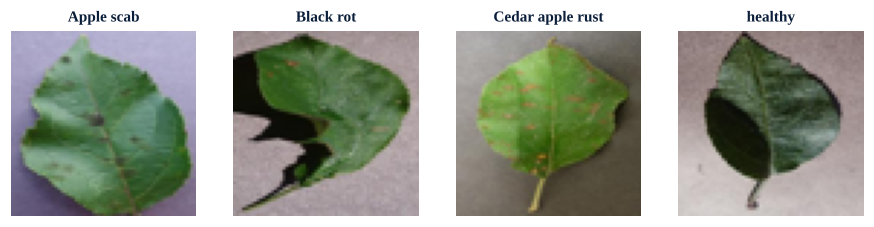

In [11]:
# Leakage check 1: exact duplicate images (would appear in both train and test after a random split)
hashes = [hashlib.md5((Xp[i] * 255).byte().numpy().tobytes()).hexdigest() for i in range(len(Xp))]
n_dup = len(hashes) - len(set(hashes))
print("exact duplicate images:", n_dup)
# Fix: keep only the first copy of each image BEFORE splitting, so a duplicate can never sit in train and test
seen, keep = set(), []
for i, hsh in enumerate(hashes):
    if hsh not in seen: seen.add(hsh); keep.append(i)
Xp, yp, hashes = Xp[keep], yp[keep], [hashes[i] for i in keep]
print("images after de-duplication:", len(yp))

# Stratified split 70 / 15 / 15 — every class keeps its share in each split
from sklearn.model_selection import train_test_split
idx_all = np.arange(len(yp))
tr_p, tmp = train_test_split(idx_all, test_size=0.30, stratify=yp, random_state=SEED)
va_p, te_p = train_test_split(tmp, test_size=0.50, stratify=yp[tmp], random_state=SEED)
tr_p, va_p, te_p = map(torch.tensor, (tr_p, va_p, te_p))
# Leakage check 2: no hash shared between train and test
print("train/test hash overlap:", len({hashes[i] for i in tr_p.tolist()} & {hashes[i] for i in te_p.tolist()}))
print("sizes  train/val/test:", len(tr_p), len(va_p), len(te_p))

pm, ps = Xp[tr_p].mean((0, 2, 3), keepdim=True), Xp[tr_p].std((0, 2, 3), keepdim=True)
Xp_n = (Xp - pm) / ps

fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
for k, a in enumerate(ax):
    i = (yp == k).nonzero()[0].item(); a.imshow(Xp[i].permute(1, 2, 0)); a.set_title(short[k], fontsize=10); a.axis("off")
plt.savefig(FIG/"s2_leaf_samples.png", bbox_inches="tight"); plt.show()

> **Real-world leakage warning:** PlantVillage photos were taken on a lab table with a uniform background.
> A model can learn the *background*, not the disease. That is why Hour 10 tests robustness.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 9 — Fine-tune and compare: CNN vs tiny Vision Transformer, Grad-CAM, error analysis

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">PlantVillage</span>
**Skills:** <span style="color:#6A3D9A">Vision Transformers, Grad-CAM, confusion-matrix error analysis</span>

In [12]:
leaf_cnn = SmallCNN(len(PV_CLASSES), c=(24, 48, 96))
print("CNN parameters:", sum(p.numel() for p in leaf_cnn.parameters()))
cnn_log = train_model(leaf_cnn, Xp_n, yp, tr_p, va_p, epochs=8, lr=3e-3)

CNN parameters: 162748


epoch 1: held-out acc 0.491  (12s)


epoch 2: held-out acc 0.855  (12s)


epoch 3: held-out acc 0.869  (13s)


epoch 4: held-out acc 0.806  (13s)


epoch 5: held-out acc 0.947  (13s)


epoch 6: held-out acc 0.973  (12s)


epoch 7: held-out acc 0.979  (12s)


epoch 8: held-out acc 0.983  (12s)


In [13]:
class TinyViT(nn.Module):
    """Patch embedding + transformer encoder + class token: the core idea of ViT in ~20 lines."""
    def __init__(self, n_classes, img=64, patch=8, dim=96, depth=4, heads=4):
        super().__init__()
        self.patch = nn.Conv2d(3, dim, patch, stride=patch)          # (B, dim, 8, 8) -> 64 tokens
        n_tokens = (img // patch) ** 2
        self.cls = nn.Parameter(torch.zeros(1, 1, dim)); self.pos = nn.Parameter(torch.randn(1, n_tokens + 1, dim) * 0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 2, dropout=0.1, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth); self.norm = nn.LayerNorm(dim); self.head = nn.Linear(dim, n_classes)
    def forward(self, x):
        t = self.patch(x).flatten(2).transpose(1, 2)
        t = torch.cat([self.cls.expand(len(t), -1, -1), t], 1) + self.pos
        return self.head(self.norm(self.encoder(t)[:, 0]))

vit = TinyViT(len(PV_CLASSES))
print("ViT parameters:", sum(p.numel() for p in vit.parameters()))
vit_log = train_model(vit, Xp_n, yp, tr_p, va_p, epochs=8, lr=1e-3)

ViT parameters: 324580


epoch 1: held-out acc 0.665  (8s)


epoch 2: held-out acc 0.764  (8s)


epoch 3: held-out acc 0.909  (7s)


epoch 4: held-out acc 0.914  (7s)


epoch 5: held-out acc 0.933  (7s)


epoch 6: held-out acc 0.928  (8s)


epoch 7: held-out acc 0.956  (8s)


epoch 8: held-out acc 0.964  (8s)


In [14]:
cmp = pd.DataFrame({"model": ["Small CNN", "Tiny ViT (from scratch)"],
                    "params": [sum(p.numel() for p in m.parameters()) for m in (leaf_cnn, vit)],
                    "val acc": [cnn_log[-1], vit_log[-1]],
                    "TEST acc": [evaluate_acc(leaf_cnn, Xp_n[te_p], yp[te_p]), evaluate_acc(vit, Xp_n[te_p], yp[te_p])]}).round(3)
cmp

,model,params,val acc,TEST acc
0,Small CNN,162748,0.983,0.987
1,Tiny ViT (from scratch),324580,0.964,0.943


**Why does the CNN usually win here?** ViTs have weaker built-in assumptions about images, so they need much more data or
**pretraining**. With a GPU in class, fine-tune a pretrained model instead:

```python
import timm   # pip install timm
model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=4)   # or "vit_small_patch16_224"
```

                  precision    recall  f1-score   support

      Apple scab      0.959     0.989     0.974        95
       Black rot      0.989     1.000     0.995        93
Cedar apple rust      1.000     0.976     0.988        41
         healthy      0.996     0.984     0.990       246

        accuracy                          0.987       475
       macro avg      0.986     0.987     0.987       475
    weighted avg      0.988     0.987     0.987       475



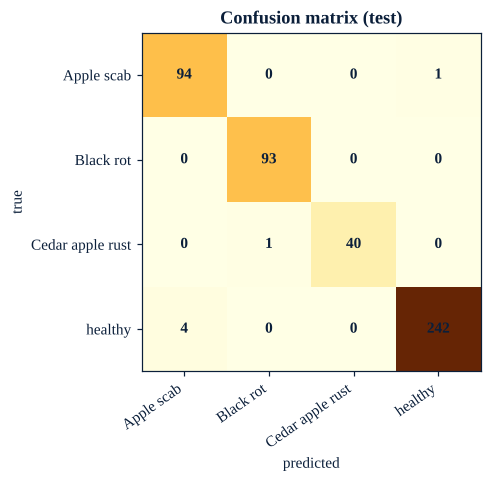

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
with torch.no_grad():
    pred_te = leaf_cnn.eval()(Xp_n[te_p]).argmax(1)
print(classification_report(yp[te_p], pred_te, target_names=short, digits=3))
cm = confusion_matrix(yp[te_p], pred_te)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="YlOrBr"); ax.set_xticks(range(4), short, rotation=35, ha="right"); ax.set_yticks(range(4), short)
for i in range(4):
    for j in range(4): ax.text(j, i, cm[i, j], ha="center", va="center", color=NAVY, fontweight="bold")
ax.set_title("Confusion matrix (test)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.savefig(FIG/"s2_confusion.png", bbox_inches="tight"); plt.show()

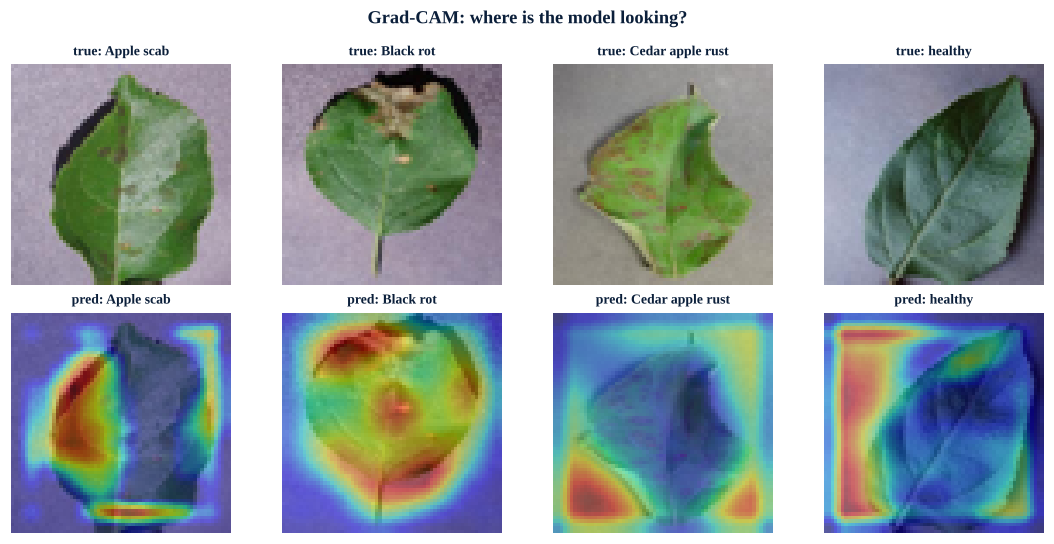

In [16]:
def grad_cam(model, x, target_layer):
    """Grad-CAM: weight each feature map by its average gradient, then ReLU."""
    acts, grads = {}, {}
    h1 = target_layer.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    h2 = target_layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))
    model.eval(); out = model(x); out[0, out.argmax(1)].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean((2, 3), keepdim=True); cam = F.relu((w * acts["a"]).sum(1)).squeeze(0)
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear")[0, 0]
    return (cam / (cam.max() + 1e-8)).detach(), out.argmax(1).item()

last_conv = [m for m in leaf_cnn.features if isinstance(m, nn.Conv2d)][-1]
fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for k in range(4):
    i = te_p[(yp[te_p] == k).nonzero()[0]].item()
    cam, p = grad_cam(leaf_cnn, Xp_n[i:i+1].clone().requires_grad_(True), last_conv)
    ax[0, k].imshow(Xp[i].permute(1, 2, 0)); ax[0, k].set_title(f"true: {short[k]}", fontsize=9)
    ax[1, k].imshow(Xp[i].permute(1, 2, 0)); ax[1, k].imshow(cam, cmap="jet", alpha=0.45); ax[1, k].set_title(f"pred: {short[p]}", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.suptitle("Grad-CAM: where is the model looking?", color=NAVY, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG/"s2_gradcam.png", bbox_inches="tight"); plt.show()

Good sign: heat on the lesions. Bad sign: heat on the background or the leaf edge — that is shortcut learning.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 10 — Robustness, INT8 quantisation, ONNX export, model card

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">PlantVillage + simulated field conditions</span>
**Skills:** <span style="color:#6A3D9A">ONNX, quantisation, model cards, distribution-shift awareness</span>

In [17]:
# Simulated field conditions (real field photos are the in-class extension): darker light, blur, sensor noise, rotation
def shift(x, kind):
    if kind == "darker (x0.6)": return x * 0.6
    if kind == "blur": return F.avg_pool2d(F.pad(x, (1, 1, 1, 1), mode="replicate"), 3, stride=1)
    if kind == "noise (sigma 0.08)": return (x + 0.08 * torch.randn_like(x)).clamp(0, 1)
    if kind == "rotate 90": return x.rot90(1, (2, 3))
    return x
rows = []
for kind in ["clean", "darker (x0.6)", "blur", "noise (sigma 0.08)", "rotate 90"]:
    xs = (shift(Xp[te_p], kind) - pm) / ps
    rows.append({"condition": kind, "CNN acc": evaluate_acc(leaf_cnn, xs, yp[te_p]), "ViT acc": evaluate_acc(vit, xs, yp[te_p])})
robust = pd.DataFrame(rows).round(3); robust

,condition,CNN acc,ViT acc
0,clean,0.987,0.943
1,darker (x0.6),0.657,0.509
2,blur,0.851,0.952
3,noise (sigma 0.08),0.200,0.918
4,rotate 90,0.958,0.916


In [18]:
# Dynamic INT8 quantisation of the Linear layers + size comparison
import io, copy
def size_kb(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.tell() / 1024
torch.backends.mha.set_fastpath_enabled(False)   # the fused inference fast-path expects float weights
# Quantise the feed-forward and head layers; keep attention projections in float
ff_layers = {n for n, m in vit.named_modules() if type(m) is nn.Linear}
q_vit = torch.ao.quantization.quantize_dynamic(copy.deepcopy(vit).eval(), ff_layers, dtype=torch.qint8)
print(f"ViT fp32: {size_kb(vit):.0f} KB  ->  INT8: {size_kb(q_vit):.0f} KB")
print("test acc fp32:", round(evaluate_acc(vit, Xp_n[te_p], yp[te_p]), 3), "| INT8:", round(evaluate_acc(q_vit, Xp_n[te_p], yp[te_p]), 3))

ViT fp32: 1286 KB  ->  INT8: 860 KB


test acc fp32: 0.943 | INT8: 0.943


In [19]:
# ONNX export of the CNN + check that ONNX Runtime gives the same answers
import onnxruntime as ort
onnx_path = "leafdoctor_cnn.onnx"
torch.onnx.export(leaf_cnn.eval(), Xp_n[:1], onnx_path, input_names=["image"], output_names=["logits"],
                  dynamic_axes={"image": {0: "batch"}}, opset_version=17, dynamo=False)
sess = ort.InferenceSession(onnx_path)
onnx_logits = sess.run(None, {"image": Xp_n[te_p[:256]].numpy()})[0]
with torch.no_grad(): torch_logits = leaf_cnn(Xp_n[te_p[:256]]).numpy()
print(f"ONNX file: {os.path.getsize(onnx_path)/1024:.0f} KB | max |diff| vs PyTorch: {np.abs(onnx_logits - torch_logits).max():.2e}")
print("same predictions:", (onnx_logits.argmax(1) == torch_logits.argmax(1)).mean())

ONNX file: 637 KB | max |diff| vs PyTorch: 2.38e-06
same predictions: 1.0


In [20]:
test_acc = cmp.loc[0, "TEST acc"]
card = f"""# Model card — LeafDoctor (Small CNN)
**Task:** classify apple-leaf photos into {', '.join(short)}.
**Data:** PlantVillage apple subset, {len(yp):,} unique lab photos at {IMG}x{IMG}; stratified 70/15/15 split; {n_dup} exact duplicates removed before splitting.
**Performance:** test accuracy {test_acc:.3f} on lab photos.
**Robustness:** accuracy under simulated field conditions ranges {robust['CNN acc'].min():.3f}–{robust['CNN acc'].max():.3f} (see table).
**Known limits:** lab background; no real field photos yet; only 4 apple classes; not a substitute for an agronomist.
**Intended use:** decision support for farmers and extension workers, with a 'not sure' option for low-confidence cases.
**Deployment:** ONNX ({os.path.getsize(onnx_path)/1024:.0f} KB), runs with ONNX Runtime on phones and edge devices.
"""
pathlib.Path("MODEL_CARD.md").write_text(card); print(card)

# Model card — LeafDoctor (Small CNN)
**Task:** classify apple-leaf photos into Apple scab, Black rot, Cedar apple rust, healthy.
**Data:** PlantVillage apple subset, 3,164 unique lab photos at 64x64; stratified 70/15/15 split; 7 exact duplicates removed before splitting.
**Performance:** test accuracy 0.987 on lab photos.
**Robustness:** accuracy under simulated field conditions ranges 0.200–0.987 (see table).
**Known limits:** lab background; no real field photos yet; only 4 apple classes; not a substitute for an agronomist.
**Intended use:** decision support for farmers and extension workers, with a 'not sure' option for low-confidence cases.
**Deployment:** ONNX (637 KB), runs with ONNX Runtime on phones and edge devices.



---
<div style="background:#FFF3E0;border-left:6px solid #FF9933;padding:12px 16px;border-radius:6px">
<b>GitHub submission — by 18:00 local time today</b><br>
1. Copy this notebook into <code>P2-leafdoctor/notebooks/</code> of your portfolio repo.<br>
2. Move reusable functions into <code>P2-leafdoctor/src/</code>, save plots into <code>results/</code>.<br>
3. Update the project README (problem, dataset, method, results, how to run, limitations &amp; ethics, AI-assistant use).<br>
4. <code>git push origin main</code> → <code>git tag -a sunday-2 -m "Sunday 2 submission"</code> → <code>git push origin sunday-2</code><br>
5. Create a GitHub Release from the tag and submit the link on the AlgoProfessor form.
</div>